# 1. Carregamento e exploração dos dados
Esta etapa tem como objetivo realizar o primeiro contato com as três bases de dados utilizadas no projeto, compreendendo sua estrutura, organização e características gerais. São verificadas as dimensões dos conjuntos de dados, as variáveis disponíveis e os tipos de informações armazenadas, estabelecendo uma visão inicial dos dados que serão utilizados nas análises.

## 1.1 Base de falas — Gilmore_Girls_Lines.csv
Esta base reúne os diálogos da série, identificando o personagem responsável por cada fala, o conteúdo do diálogo e a temporada correspondente. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/Gilmore_Girls_Lines.csv")

In [3]:
df.head()

,Unnamed: 0,Character,Line,Season
0,0,Lorelai,"Please, Luke. Please, please, please.",1
1,1,Luke,How many cups have you had this morning?,1
2,2,Lorelai,None.,1
3,3,Luke,Plus...,1
4,4,Lorelai,"Five, but yours is better.",1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115205 entries, 0 to 115204
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   Unnamed: 0  115205 non-null  int64
 1   Character   115204 non-null  str  
 2   Line        115199 non-null  str  
 3   Season      115205 non-null  int64
dtypes: int64(2), str(2)
memory usage: 3.5 MB


## 1.2 Base de personagens — characters_info.csv
Esta base reúne informações sobre os personagens da série, incluindo seus nomes, intérpretes e quantidade de episódios em que aparecem. 

In [5]:
df_personagens = pd.read_csv("../data/raw/characters_info.csv", sep="\t")

In [6]:
df_personagens.head()

,full name,portrayed by,num_episodes,name
0,A.K.,mentioned,1,A.K.
1,Al,mentioned,1,Al
2,Alex Lesman,Billy Burke,3,Alex
3,Allen Prescott,Richard Fancy,1,Allen
4,Andrew,Mike Gandolfi,22,Andrew


In [7]:
df_personagens.info()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   full name     155 non-null    str  
 1   portrayed by  155 non-null    str  
 2   num_episodes  155 non-null    int64
 3   name          155 non-null    str  
dtypes: int64(1), str(3)
memory usage: 5.0 KB


## 1.3 Base de episódios — gilmore_girls_episodes.csv
Esta base reúne informações sobre os episódios da série, como temporada, número do episódio, título, sinopse, elenco, equipe de produção e avaliações.

In [8]:
df_episodios = pd.read_csv("../data/raw/gilmore_girls_episodes.csv")

In [9]:
df_episodios.head()

,series_id,season_number,episode_number,Actors,Awards,Country,Director,Episode,Genre,Language,...,Runtime,Season,Title,Type,Writer,Year,imdbID,imdbRating,imdbVotes,seriesID
0,tt0238784,1,0,"Lauren Graham, Alexis Bledel, Keiko Agena",NaN,NaN,Lesli Linka Glatter,0,"Comedy, Drama",NaN,...,44 min,1,Unaired Pilot,episode,Amy Sherman-Palladino,2007,tt0931812,NaN,186,tt0238784
1,tt0238784,1,1,"Lauren Graham, Alexis Bledel, Melissa McCarthy",NaN,United States,Lesli Linka Glatter,1,"Comedy, Drama",English,...,45 min,1,Pilot,episode,Amy Sherman-Palladino,2000,tt0588176,8.1,1949,tt0238784
2,tt0238784,1,2,"Lauren Graham, Alexis Bledel, Melissa McCarthy",NaN,United States,Arlene Sanford,2,"Comedy, Drama",English,...,44 min,1,The Lorelais' First Day at Chilton,episode,Amy Sherman-Palladino,2000,tt0588209,8.0,1533,tt0238784
3,tt0238784,1,3,"Lauren Graham, Alexis Bledel, Melissa McCarthy",NaN,United States,Adam Nimoy,3,"Comedy, Drama",English,...,43 min,1,Kill Me Now,episode,"Amy Sherman-Palladino, Joanne T. Waters",2000,tt0588157,NaN,1217,tt0238784
4,tt0238784,1,4,"Lauren Graham, Alexis Bledel, Melissa McCarthy",NaN,United States,Alan Myerson,4,"Comedy, Drama",English,...,44 min,1,The Deer Hunters,episode,"Amy Sherman-Palladino, Jed Seidel",2000,tt0588202,NaN,1328,tt0238784


In [10]:
df_episodios.info()

<class 'pandas.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   series_id         154 non-null    str    
 1   season_number     154 non-null    int64  
 2   episode_number    154 non-null    int64  
 3   Actors            152 non-null    str    
 4   Awards            0 non-null      float64
 5   Country           150 non-null    str    
 6   Director          152 non-null    str    
 7   Episode           154 non-null    int64  
 8   Genre             154 non-null    str    
 9   Language          153 non-null    str    
 10  Metascore         0 non-null      float64
 11  Plot              153 non-null    str    
 12  Poster            154 non-null    str    
 13  Rated             153 non-null    str    
 14  Ratings           89 non-null     str    
 15  Ratings.0.Source  65 non-null     str    
 16  Ratings.0.Value   65 non-null     str    
 17  Released

# 2. Qualidade e tratamento dos dados
Nesta etapa, são avaliadas a qualidade e a consistência das três bases de dados, buscando identificar possíveis problemas que possam comprometer as análises. Também são realizados ajustes na estrutura dos arquivos e verificações de valores ausentes e registros duplicados, preservando as informações originais sempre que possível.

## 2.1 Base de falas — Gilmore_Girls_Lines.csv
O objetivo desta etapa é verificar a estrutura das colunas e identificar informações redundantes ou desnecessárias. Os ajustes realizados buscam simplificar a base e garantir que ela contenha apenas as variáveis relevantes para as análises.

In [11]:
df["Unnamed: 0"].equals(df.index.to_series())

True

In [12]:
df = df.drop(columns=["Unnamed: 0"])

In [13]:
df.head()

,Character,Line,Season
0,Lorelai,"Please, Luke. Please, please, please.",1
1,Luke,How many cups have you had this morning?,1
2,Lorelai,None.,1
3,Luke,Plus...,1
4,Lorelai,"Five, but yours is better.",1


A coluna `Unnamed: 0` foi removida por apresentar valores idênticos ao índice do DataFrame, não acrescentando informações à análise.

## 2.2 Análise de valores ausentes
Nesta etapa, será realizada a identificação e a quantificação dos valores ausentes em cada variável, permitindo conhecer sua ocorrência e distribuição na base de dados. Os resultados servirão de referência para avaliar a necessidade de tratamento nas próximas etapas.

In [14]:
df.isnull().sum()

Character    1
Line         6
Season       0
dtype: int64

Foram identificados 7 registros com valores ausentes: 1 sem identificação de personagem e 6 sem conteúdo de fala. Os registros serão preservados na base original, com tratamento específico conforme a necessidade de cada análise.

# 3. Análise exploratória
Esta etapa tem como objetivo realizar uma análise inicial dos dados, explorando a distribuição das falas entre os personagens e as temporadas. Busca-se obter uma visão geral das características do conjunto de dados e identificar aspectos que possam ser aprofundados nas próximas etapas do projeto.

## 3.1 Distribuição das falas por personagem
Esta análise apresenta a distribuição das falas entre os personagens, considerando a quantidade e a participação percentual de cada um. O objetivo é obter uma visão geral da frequência de participação dos personagens nos diálogos da série.

In [15]:
frequencia_personagens = df["Character"].value_counts()

analise_personagens = pd.DataFrame({
    "Quantidade de falas": frequencia_personagens,
    "Participação (%)": (frequencia_personagens / len(df) * 100).round(2)
})

analise_personagens.head(15)

,Quantidade de falas,Participação (%)
Character,,
Lorelai,31670,27.49
Rory,23689,20.56
Luke,9749,8.46
Emily,6577,5.71
Sookie,4375,3.80
Richard,3383,2.94
Lane,3211,2.79
Paris,2984,2.59
Logan,2402,2.08


A análise permite identificar os personagens com maior participação nos diálogos. Lorelai e Rory se destacam como as personagens com maior participação nos diálogos, concentrando a maior parcela das falas entre os personagens. Luke, Emily e Sookie aparecem na sequência.

## 3.2 Distribuição das falas por temporada
Esta análise apresenta a distribuição da quantidade de falas entre as sete temporadas, considerando também a participação percentual de cada uma no total. O objetivo é conhecer o volume de diálogos registrado em cada temporada e obter uma visão geral de sua distribuição ao longo da série.

In [16]:
falas_por_temporada = df["Season"].value_counts().sort_index()

analise_temporadas = pd.DataFrame({
    "Quantidade de falas": falas_por_temporada,
    "Participação (%)": (falas_por_temporada / len(df) * 100).round(2)
})

analise_temporadas

,Quantidade de falas,Participação (%)
Season,,
1,15271,13.26
2,18069,15.68
3,17409,15.11
4,17631,15.30
5,16032,13.92
6,15745,13.67
7,15048,13.06


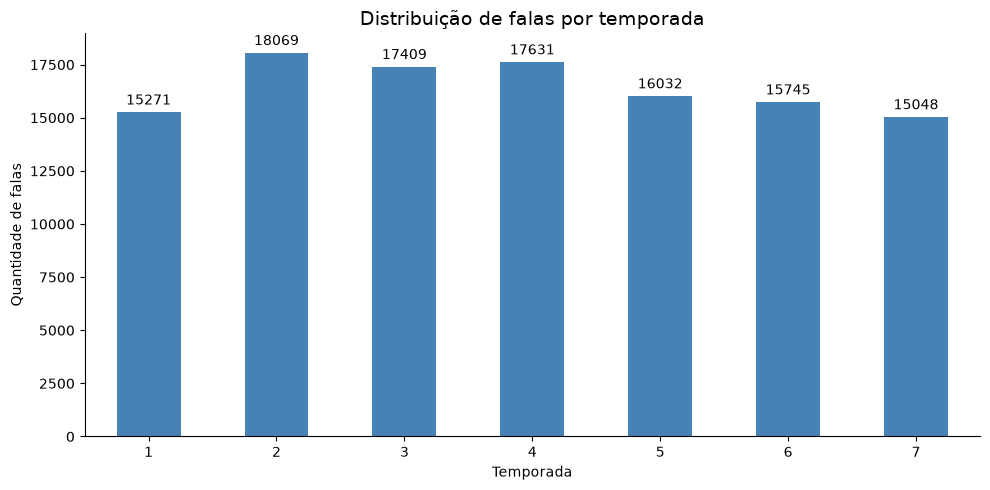

In [17]:
plt.figure(figsize=(10, 5))

ax = falas_por_temporada.plot(kind="bar", color="steelblue")

plt.title("Distribuição de falas por temporada", fontsize=14)
plt.xlabel("Temporada")
plt.ylabel("Quantidade de falas")
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

A segunda temporada apresentou o maior volume de falas (18.069), enquanto a sétima apresentou o menor (15.048). A distribuição entre as temporadas foi relativamente equilibrada, com participação entre 13,06% e 15,68% do total.

## 4. Conhecimento das bases complementares

## 4.1 Informações dos personagens

## 5. Síntese da exploração inicial
A exploração inicial permitiu conhecer a estrutura da base e obter uma visão geral da distribuição das falas. Foram identificadas diferenças na frequência de participação dos personagens e no volume de diálogos entre as temporadas.

Também foram observados valores ausentes e diferentes identificações de personagens, aspectos que serão considerados nas próximas etapas de preparação e análise dos dados.
